# 3. People: do films made by the same people earn alike?

**Method.** Link two films that share a director, a top-three billed actor, a producer or a studio. Assortativity is the correlation of the two films' returns, after removing budget, era and genre. Then split the network into communities with Louvain.

**Compared to what?** 1,000 shuffles of returns within era bins that keep the network. For communities, the network rewired with every film's degree kept. For their returns, shuffles within budget decile.

**What it misses.** A shared person also means a shared era, budget tier and company, so this doesn't show the person causes it. Only films with money data are tested, all with 10,000+ votes.

The runs declared before running are in `src/analysis/network/Q2_NETWORK.md`.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").exists())
A = ROOT / "src" / "analysis"
pd.set_option("display.max_colwidth", 90)

## Assortativity by role, common set

In [2]:
q = json.loads((A / "network/q2_network.json").read_text())["samples"]
def tab(k):
    return pd.DataFrame({r: {c: v[c] for c in ("pairs", "assortativity", "null_mean", "null_95", "p")} for r, v in q[k].items() if isinstance(v, dict) and "null_95" in v}).T
tab("in_common_set_adjusted").round(4)

,pairs,assortativity,null_mean,null_95,p
director,2311.0,0.0904,-0.0005,0.0354,0.001
actor,9958.0,0.0642,-0.0015,0.0138,0.001
producer,6639.0,0.0910,-0.0006,0.0201,0.001
studio,20990.0,0.0478,-0.0012,0.0103,0.001
combined,33685.0,0.0477,-0.0009,0.0076,0.001


The same on every film with usable money.

In [3]:
tab("usable_money_adjusted").round(4)

,pairs,assortativity,null_mean,null_95,p
director,16156.0,0.1163,-0.0006,0.0133,0.001
actor,92131.0,0.0419,-0.0003,0.0050,0.001
producer,62143.0,0.1155,-0.0003,0.0067,0.001
studio,231646.0,0.0615,-0.0004,0.0029,0.001
combined,353777.0,0.0551,-0.0003,0.0024,0.001


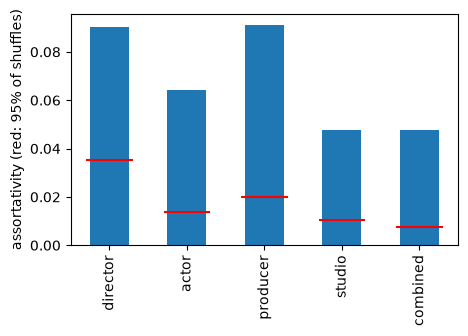

In [4]:
t = tab("in_common_set_adjusted")
ax = t.assortativity.plot.bar(figsize=(5, 3), color="tab:blue")
ax.hlines(t.null_95, [i - .3 for i in range(len(t))], [i + .3 for i in range(len(t))], color="red"); ax.set_ylabel("assortativity (red: 95% of shuffles)"); plt.show()

## Does it need a shared genre?

In [5]:
b = pd.read_csv(A / "compare/outputs/network_by_genre/assortativity_by_genre.csv")
b[b.split.isin(["all", "same genre", "different genre"])].round(4)

,sample,role,split,pairs,assortativity,null_mean,null_95,p,p_holm_within_role
0,in_common_set,director,all,2311,0.0904,-0.0005,0.0354,0.001,NaN
1,in_common_set,director,same genre,1809,0.0946,-0.0007,0.0382,0.001,NaN
2,in_common_set,director,different genre,502,0.0744,-0.0011,0.0722,0.044,NaN
9,in_common_set,actor,all,9958,0.0642,-0.0010,0.0163,0.001,NaN
10,in_common_set,actor,same genre,7002,0.0683,-0.0008,0.0192,0.001,NaN
11,in_common_set,actor,different genre,2956,0.0538,-0.0016,0.0315,0.001,NaN
20,in_common_set,producer,all,6639,0.0910,-0.0014,0.0200,0.001,NaN
21,in_common_set,producer,same genre,5065,0.0957,-0.0015,0.0221,0.001,NaN
22,in_common_set,producer,different genre,1574,0.0743,-0.0014,0.0373,0.004,NaN
32,in_common_set,studio,all,20990,0.0478,-0.0015,0.0098,0.001,NaN


## Communities

Modularity against the rewired network, and how well 10 Louvain seeds agree (NMI). Modularity says how grouped the network is, not whether the groups are right.

In [6]:
c = json.loads((A / "compare/outputs/communities_usable_money/summary.json").read_text())
pd.Series({k: v for k, v in c.items() if not isinstance(v, (dict, list))}).to_frame("value")

,value
set,usable_money
link_types,credits
films,6346
films_in_network,6285
links,353777
seeds,10
communities,26
communities_min_size,16
min_size,30
films_in_big_communities,6250


In [7]:
p = pd.read_csv(A / "compare/outputs/communities_usable_money/community_profiles.csv")
p[["films", "median_budget_musd", "median_multiple", "excess", "p_holm", "top_studios"]].sort_values("excess", ascending=False).round(3)

,films,median_budget_musd,median_multiple,excess,p_holm,top_studios
12,108,8.1,5.59,1.063,0.002,Blumhouse Productions (71); Platinum Dunes (14); IM Global (14)
15,73,30.0,3.25,0.487,0.008,Walt Disney Animation Studios (40); Studio Ghibli (9); Disney Television Animation (3)
9,196,34.0,2.61,0.280,0.020,Paramount Pictures (99); Di Bonaventura Pictures (30); Nickelodeon Movies (23)
4,542,23.0,2.39,0.218,0.003,Amblin Entertainment (55); DreamWorks Pictures (54); Participant (company) (37)
8,358,30.0,2.19,0.172,0.057,Universal Pictures (135); Relativity Media (64); Imagine Entertainment (55)
11,171,20.0,2.20,0.127,1.000,StudioCanal (91); Working Title Films (84); Relativity Media (15)
6,408,43.5,2.24,0.101,0.481,Columbia Pictures (356); Revolution Studios (43); Relativity Media (37)
13,94,18.6,2.98,0.070,1.000,Marvel Studios (27); CJ Entertainment (8); Rysher Entertainment (3)
2,628,23.0,2.02,0.058,1.000,Touchstone Pictures (133); Walt Disney Pictures (128); Jerry Bruckheimer Films (31)
3,580,30.0,2.26,0.037,1.000,Regency Enterprises (104); 20th Century Studios (79); RatPac Entertainment (63)


Without studio links, the same test.

In [8]:
p = pd.read_csv(A / "compare/outputs/communities_usable_money_no_studio/community_profiles.csv")
p[p.p_holm < .05][["films", "median_budget_musd", "excess", "p_holm", "top_studios"]].round(3)

,films,median_budget_musd,excess,p_holm,top_studios
3,394,32.0,0.249,0.005,Amblin Entertainment (57); Imagine Entertainment (52); Malpaso Productions (34)
15,197,30.0,0.291,0.022,Columbia Pictures (49); Happy Madison Productions (32); Mandeville Films (19)
17,181,10.0,0.531,0.003,Blumhouse Productions (71); Platinum Dunes (22); New Line Cinema (19)


## Without the vote cut: all of IMDb, and Hollywood inside it

The network rebuilt from every non-adult IMDb film (people only, since IMDb records no studios), then Louvain again inside its largest group, Hollywood. Returns are still known only for the films with usable money, so only groups with at least 30 of them are tested. `differ` counts the groups that differ from films of the same budget after Holm correction.

In [9]:
rows = []
for name, d in [("main", "communities_usable_money"), ("no studios", "communities_usable_money_no_studio"),
                ("all of IMDb", "communities_full_imdb"), ("Hollywood", "communities_hollywood")]:
    k = json.loads((A / f"compare/outputs/{d}/summary.json").read_text())
    pr = pd.read_csv(A / f"compare/outputs/{d}/community_profiles.csv")
    rows.append({"network": name, "films": k.get("films_in_network", k["films"]) if "films" in k else k["films_in_network"],
                 "groups": k["communities"], "modularity": k["modularity"], "rewired max": k["rewired_modularity_max"],
                 "NMI of seeds": k["mean_nmi_best_vs_other_seeds"], "tested": len(pr), "differ": int((pr.p_holm < .05).sum())})
pd.DataFrame(rows).round(3)

,network,films,groups,modularity,rewired max,NMI of seeds,tested,differ
0,main,6285,26,0.493,0.085,0.692,16,7
1,no studios,6240,40,0.451,0.124,0.631,26,3
2,all of IMDb,656445,15894,0.893,0.081,0.891,7,0
3,Hollywood,136577,55,0.595,0.126,0.505,25,7


The groups inside Hollywood that differ. This split is less stable, so the edges of single groups shouldn't be read closely.

In [10]:
h = pd.read_csv(A / "compare/outputs/communities_hollywood/community_profiles.csv")
h[h.p_holm < .05][["usable_films", "median_budget_musd", "excess", "p_holm", "top_studios"]].sort_values("excess", ascending=False)

,usable_films,median_budget_musd,excess,p_holm,top_studios
23,31,6.0,0.9714,0.0266,Dog Eat Dog Films (6); Broken Lizard (4); Cataland Films (4)
20,40,6.0,0.8841,0.0260,Kingdom Story Company (4); TriStar Pictures (3); Sherwood Pictures (3)
4,299,16.0,0.4311,0.0025,Blumhouse Productions (71); Di Bonaventura Pictures (32); Vertigo Entertainment (27)
5,232,40.0,0.3513,0.0025,Imagine Entertainment (56); Amblin Entertainment (38); Malpaso Productions (32)
3,308,25.2,-0.3179,0.0025,Emmett/Furla/Oasis Films (19); Tribeca Enterprises (18); Columbia Pictures (16)
10,141,30.0,-0.3957,0.0126,Thunder Road Films (24); Constantin Film (15); Impact Pictures (12)
16,55,12.5,-0.8415,0.0025,Columbia Pictures (3); Point Grey Pictures (3); Hydraulx (3)


## Do people do better in a genre they know?

Coefficients per standard deviation, with experience counted over every earlier IMDb film.

In [11]:
e = pd.read_csv(A / "genre/outputs/before_release/specialists_ols.csv")
e[e.films.str.contains("all earlier IMDb")].round(4)

,films,term,coef_per_sd,lo,hi,p,n
0,"history: all earlier IMDb movies, sequel flag controlled",genre_experience,0.0844,0.0318,0.1369,0.0016,6316
1,"history: all earlier IMDb movies, sequel flag controlled",prior_credits,-0.0133,-0.0584,0.0319,0.5640,6316
2,"history: all earlier IMDb movies, sequel flag controlled",genre_breadth,-0.0772,-0.1287,-0.0258,0.0033,6316
3,"history: all earlier IMDb movies, sequels left out",genre_experience,0.0701,0.0086,0.1317,0.0255,5533
4,"history: all earlier IMDb movies, sequels left out",prior_credits,-0.0231,-0.0720,0.0258,0.3550,5533
5,"history: all earlier IMDb movies, sequels left out",genre_breadth,-0.0760,-0.1314,-0.0206,0.0072,5533
